In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100

study_hours = np.random.uniform(1, 8, n)
attendance = np.random.uniform(60, 100, n)
previous_score = np.random.uniform(40, 95, n)
sleep_hours = np.random.uniform(5, 9, n)

noise = np.random.normal(0, 4, n)

math_score = (
    0.40 * previous_score
    + 3.5 * study_hours
    + 0.15 * attendance
    + 1.5 * sleep_hours
    + noise
)

math_score = np.clip(math_score, 0, 100)

df = pd.DataFrame({
    "Study_Hours": study_hours.round(2),
    "Attendance": attendance.round(2),
    "Previous_Score": previous_score.round(2),
    "Sleep_Hours": sleep_hours.round(2),
    "Math_Score": math_score.round(2)
})

print("Dataset created successfully!")
print(df.head())

Dataset created successfully!
   Study_Hours  Attendance  Previous_Score  Sleep_Hours  Math_Score
0         3.62       61.26           75.31         5.21       65.02
1         7.66       85.46           44.63         7.13       68.23
2         6.12       72.57           48.89         7.16       65.35
3         5.19       80.34           89.42         7.55       76.07
4         2.09       96.30           73.35         7.90       64.26


In [2]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (100, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     100 non-null    float64
 1   Attendance      100 non-null    float64
 2   Previous_Score  100 non-null    float64
 3   Sleep_Hours     100 non-null    float64
 4   Math_Score      100 non-null    float64
dtypes: float64(5)
memory usage: 4.0 KB
None

Statistical Summary:
       Study_Hours  Attendance  Previous_Score  Sleep_Hours  Math_Score
count    100.00000  100.000000      100.000000   100.000000  100.000000
mean       4.29180   79.913200       68.468300     6.964000   64.995000
std        2.08272   11.724675       16.138933     1.173838    9.474312
min        1.04000   60.280000       40.280000     5.060000   38.660000
25%        2.35000   69.677500       55.227500     5.997500   59.127500
50%        4.25000   80.225000       

In [3]:
df.to_csv("student_performance.csv", index=False)

from google.colab import files

files.download("student_performance.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import pandas as pd
import numpy as np

df = pd.read_csv("student_performance.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   Study_Hours  Attendance  Previous_Score  Sleep_Hours  Math_Score
0         3.62       61.26           75.31         5.21       65.02
1         7.66       85.46           44.63         7.13       68.23
2         6.12       72.57           48.89         7.16       65.35
3         5.19       80.34           89.42         7.55       76.07
4         2.09       96.30           73.35         7.90       64.26


In [5]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape:
(100, 5)

Column Names:
Index(['Study_Hours', 'Attendance', 'Previous_Score', 'Sleep_Hours',
       'Math_Score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     100 non-null    float64
 1   Attendance      100 non-null    float64
 2   Previous_Score  100 non-null    float64
 3   Sleep_Hours     100 non-null    float64
 4   Math_Score      100 non-null    float64
dtypes: float64(5)
memory usage: 4.0 KB


In [6]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Study_Hours       0
Attendance        0
Previous_Score    0
Sleep_Hours       0
Math_Score        0
dtype: int64


In [7]:
print("Statistical Summary:")
print(df.describe())

Statistical Summary:
       Study_Hours  Attendance  Previous_Score  Sleep_Hours  Math_Score
count    100.00000  100.000000      100.000000   100.000000  100.000000
mean       4.29180   79.913200       68.468300     6.964000   64.995000
std        2.08272   11.724675       16.138933     1.173838    9.474312
min        1.04000   60.280000       40.280000     5.060000   38.660000
25%        2.35000   69.677500       55.227500     5.997500   59.127500
50%        4.25000   80.225000       70.940000     7.040000   65.555000
75%        6.11250   90.645000       81.382500     7.942500   71.240000
max        7.91000   99.430000       94.450000     8.960000   89.030000


In [8]:
correlation = df.corr(numeric_only=True)

print("Correlation Between Student Performance Features:")
print(correlation)

Correlation Between Student Performance Features:
                Study_Hours  Attendance  Previous_Score  Sleep_Hours  \
Study_Hours        1.000000   -0.034034       -0.037669    -0.211855   
Attendance        -0.034034    1.000000       -0.146347    -0.011649   
Previous_Score    -0.037669   -0.146347        1.000000    -0.214757   
Sleep_Hours       -0.211855   -0.011649       -0.214757     1.000000   
Math_Score         0.669820    0.051237        0.556269    -0.087884   

                Math_Score  
Study_Hours       0.669820  
Attendance        0.051237  
Previous_Score    0.556269  
Sleep_Hours      -0.087884  
Math_Score        1.000000  


In [9]:
math_correlation = correlation["Math_Score"].sort_values(
    ascending=False
)

print("Factors Related to Mathematics Score:")
print(math_correlation)

Factors Related to Mathematics Score:
Math_Score        1.000000
Study_Hours       0.669820
Previous_Score    0.556269
Attendance        0.051237
Sleep_Hours      -0.087884
Name: Math_Score, dtype: float64


In [10]:
average_score = df["Math_Score"].mean()

print("Average Mathematics Score:", round(average_score, 2))

Average Mathematics Score: 65.0


In [11]:
highest = df.loc[df["Math_Score"].idxmax()]
lowest = df.loc[df["Math_Score"].idxmin()]

print("Highest Mathematics Score:")
print(highest)

print("\nLowest Mathematics Score:")
print(lowest)

Highest Mathematics Score:
Study_Hours        6.71
Attendance        69.06
Previous_Score    90.23
Sleep_Hours        7.73
Math_Score        89.03
Name: 73, dtype: float64

Lowest Mathematics Score:
Study_Hours        1.52
Attendance        61.63
Previous_Score    59.77
Sleep_Hours        5.78
Math_Score        38.66
Name: 68, dtype: float64


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


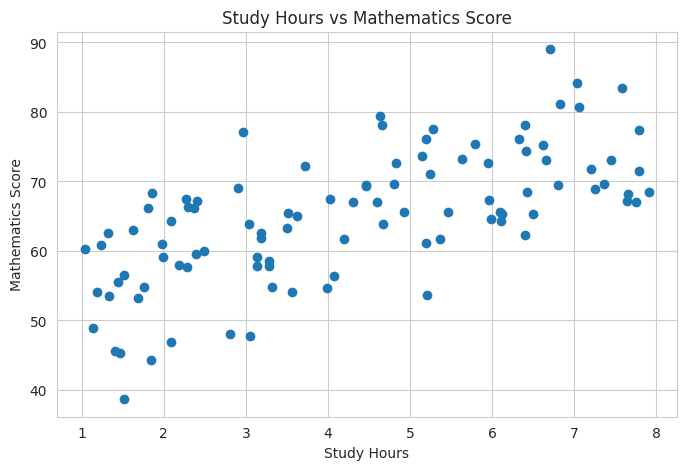

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Study_Hours"], df["Math_Score"])

plt.title("Study Hours vs Mathematics Score")
plt.xlabel("Study Hours")
plt.ylabel("Mathematics Score")

plt.show()

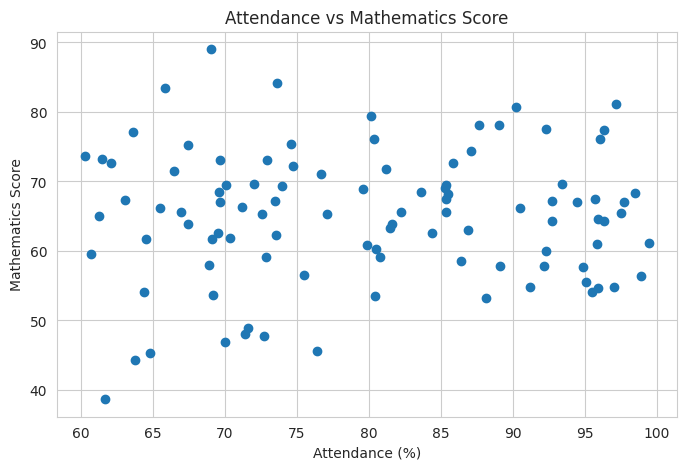

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Attendance"], df["Math_Score"])

plt.title("Attendance vs Mathematics Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Mathematics Score")

plt.show()

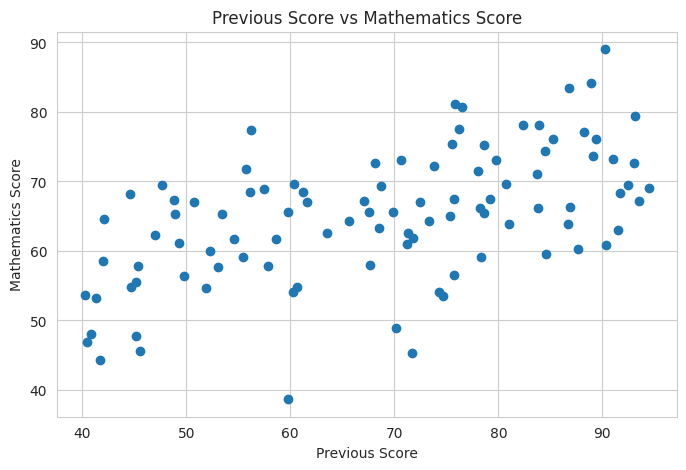

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Previous_Score"], df["Math_Score"])

plt.title("Previous Score vs Mathematics Score")
plt.xlabel("Previous Score")
plt.ylabel("Mathematics Score")

plt.show()

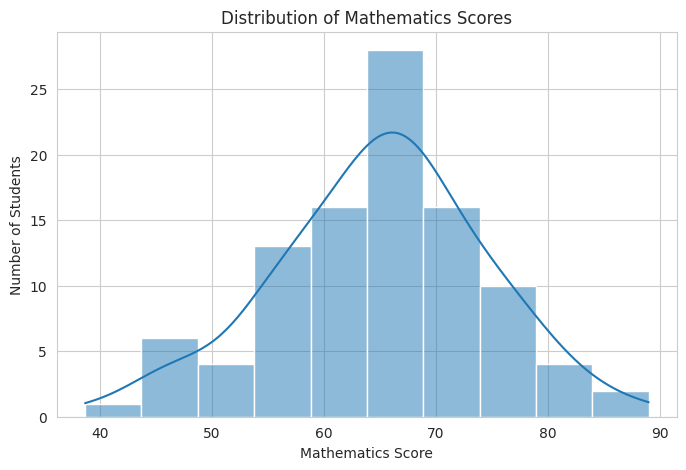

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Math_Score"], bins=10, kde=True)

plt.title("Distribution of Mathematics Scores")
plt.xlabel("Mathematics Score")
plt.ylabel("Number of Students")

plt.show()

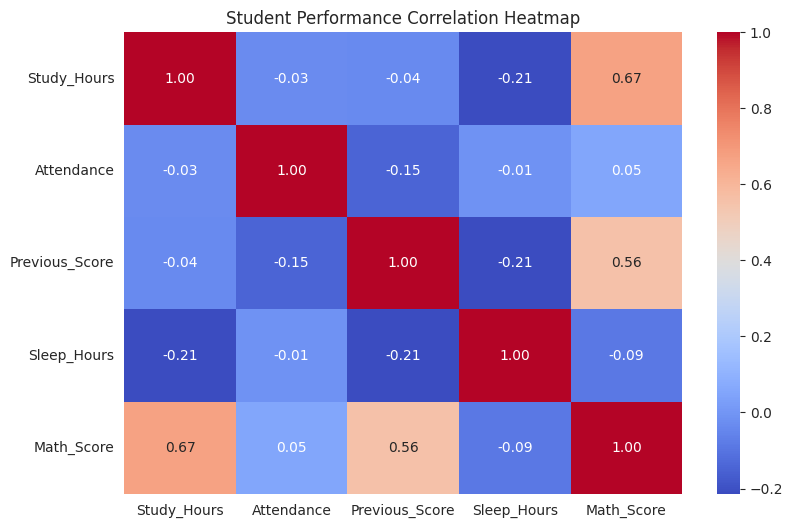

In [17]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Student Performance Correlation Heatmap")

plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [19]:
X = df[[
    "Study_Hours",
    "Attendance",
    "Previous_Score",
    "Sleep_Hours"
]]

y = df["Math_Score"]

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   Study_Hours  Attendance  Previous_Score  Sleep_Hours
0         3.62       61.26           75.31         5.21
1         7.66       85.46           44.63         7.13
2         6.12       72.57           48.89         7.16
3         5.19       80.34           89.42         7.55
4         2.09       96.30           73.35         7.90

Target Values:
0    65.02
1    68.23
2    65.35
3    76.07
4    64.26
Name: Math_Score, dtype: float64


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80, 4)
Testing data: (20, 4)


In [21]:
model = LinearRegression()

print("Linear Regression model created successfully!")

Linear Regression model created successfully!


In [22]:
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [23]:
y_pred = model.predict(X_test)

print("Actual Mathematics Scores:")
print(y_test.values[:10])

print("\nPredicted Mathematics Scores:")
print(y_pred[:10].round(2))

Actual Mathematics Scores:
[55.57 68.86 74.36 73.26 48.07 56.46 47.79 84.2  48.92 65.02]

Predicted Mathematics Scores:
[51.59 68.22 75.92 76.41 47.95 56.71 52.48 78.1  53.61 59.57]


In [24]:
new_student = pd.DataFrame({
    "Study_Hours": [5],
    "Attendance": [90],
    "Previous_Score": [75],
    "Sleep_Hours": [7]
})

predicted_score = model.predict(new_student)

print("Predicted Mathematics Score:",
      round(predicted_score[0], 2))

Predicted Mathematics Score: 71.06


In [25]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [26]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 3.15


In [27]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", round(mse, 2))

Mean Squared Error: 15.08


In [28]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 4))

R2 Score: 0.9042


In [29]:
print("STUDENT PERFORMANCE MODEL EVALUATION")
print("------------------------------------")

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("R2 Score:", round(r2, 4))

STUDENT PERFORMANCE MODEL EVALUATION
------------------------------------
MAE: 3.15
MSE: 15.08
R2 Score: 0.9042


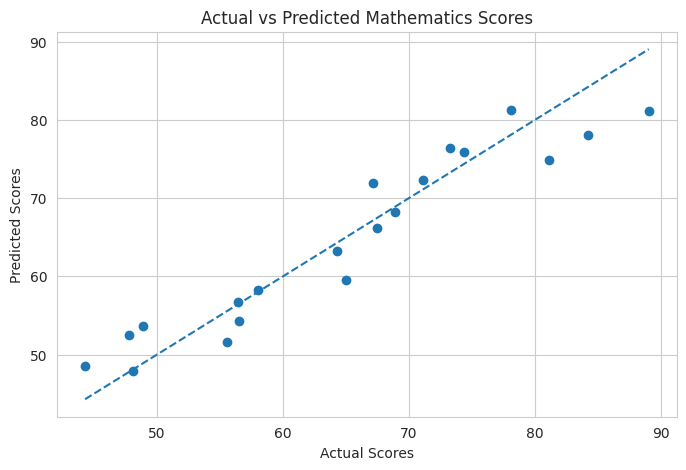

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Mathematics Scores")
plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")

plt.show()

In [31]:
!pip install gradio

In [32]:
import gradio as gr

print("Gradio imported successfully!")

Gradio imported successfully!


In [33]:
def predict_score(study_hours, attendance, previous_score, sleep_hours):

    student_data = pd.DataFrame({
        "Study_Hours": [study_hours],
        "Attendance": [attendance],
        "Previous_Score": [previous_score],
        "Sleep_Hours": [sleep_hours]
    })

    prediction = model.predict(student_data)

    return round(float(prediction[0]), 2)

In [34]:
app = gr.Interface(
    fn=predict_score,

    inputs=[
        gr.Slider(1, 8, value=5, label="Study Hours"),
        gr.Slider(60, 100, value=90, label="Attendance (%)"),
        gr.Slider(40, 95, value=75, label="Previous Score"),
        gr.Slider(5, 9, value=7, label="Sleep Hours")
    ],

    outputs=gr.Number(label="Predicted Mathematics Score"),

    title="Student Performance Prediction System",

    description="Enter student details to predict the Mathematics score using Machine Learning."
)

print("Gradio application created successfully!")

Gradio application created successfully!


In [35]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://77758e15939c03cdd7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
